# *Credit Card Default Classification*
Predicting customer payment default probability using demographic indicators, historical credit repayment behavior, and billing statements.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', 100)


In [2]:
df = pd.read_csv("data/UCI_Credit_Card.csv")


--------------
# *Data Inspection*
--------------


In [3]:
df.shape


(30000, 25)


In [4]:
df.head()


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,-2,-2,3913.0,3102.0,689.0,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,0,2,2682.0,1725.0,2682.0,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,0,0,29239.0,14027.0,13559.0,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,0,0,46990.0,48233.0,49291.0,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,0,0,8617.0,5670.0,35835.0,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


In [5]:
df.sample(5)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
12636,12637,50000.0,2,2,2,24,1,-2,-1,-1,0,0,0.0,0.0,51400.0,11330.0,12144.0,12938.0,0.0,51400.0,11330.0,1000.0,1000.0,1519.0,0
13135,13136,260000.0,1,1,2,30,-1,-1,-1,0,0,-1,496.0,496.0,992.0,992.0,496.0,1488.0,496.0,992.0,496.0,0.0,1488.0,496.0,0
12652,12653,100000.0,1,3,2,29,0,0,0,0,0,-2,47919.0,30820.0,28503.0,6810.0,-3.0,-3.0,2000.0,1000.0,1039.0,12920.0,0.0,0.0,0
22697,22698,500000.0,2,2,1,35,0,0,0,0,0,0,286595.0,292813.0,302966.0,300000.0,400000.0,0.0,11000.0,14846.0,6000.0,100000.0,0.0,279260.0,0
20978,20979,50000.0,1,2,1,41,0,0,0,0,0,0,43607.0,45375.0,46836.0,48635.0,19373.0,20129.0,2500.0,2500.0,3000.0,1500.0,2000.0,3000.0,0


In [6]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   ID                          30000 non-null  int64  
 1   LIMIT_BAL                   30000 non-null  float64
 2   SEX                         30000 non-null  int64  
 3   EDUCATION                   30000 non-null  int64  
 4   MARRIAGE                    30000 non-null  int64  
 5   AGE                         30000 non-null  int64  
 6   PAY_0                       30000 non-null  int64  
 7   PAY_2                       30000 non-null  int64  
 8   PAY_3                       30000 non-null  int64  
 9   PAY_4                       30000 non-null  int64  
 10  PAY_5                       30000 non-null  int64  
 11  PAY_6                       30000 non-null  int64  
 12  BILL_AMT1                   30000 non-null  float64
 13  BILL_AMT2                   30000 non-null

In [7]:
df.describe()


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,3.000000e+04,30000.000000,30000.000000,30000.000000,30000.000000,3.000000e+04,30000.00000,30000.000000,30000.000000,30000.000000,30000.000000
mean,15000.500000,167484.322667,1.603733,1.853133,1.551867,35.485500,-0.016700,-0.133767,-0.166200,-0.220667,-0.266200,-0.291100,51223.330900,49179.075167,4.701315e+04,43262.948967,40311.400967,38871.760400,5663.580500,5.921163e+03,5225.68150,4826.076867,4799.387633,5215.502567,0.221200
std,8660.398374,129747.661567,0.489129,0.790349,0.521970,9.217904,1.123802,1.197186,1.196868,1.169139,1.133187,1.149988,73635.860576,71173.768783,6.934939e+04,64332.856134,60797.155770,59554.107537,16563.280354,2.304087e+04,17606.96147,15666.159744,15278.305679,17777.465775,0.415062
min,1.000000,10000.000000,1.000000,0.000000,0.000000,21.000000,-2.000000,-2.000000,-2.000000,-2.000000,-2.000000,-2.000000,-165580.000000,-69777.000000,-1.572640e+05,-170000.000000,-81334.000000,-339603.000000,0.000000,0.000000e+00,0.00000,0.000000,0.000000,0.000000,0.000000
25%,7500.750000,50000.000000,1.000000,1.000000,1.000000,28.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,3558.750000,2984.750000,2.666250e+03,2326.750000,1763.000000,1256.000000,1000.000000,8.330000e+02,390.00000,296.000000,252.500000,117.750000,0.000000
50%,15000.500000,140000.000000,2.000000,2.000000,2.000000,34.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,22381.500000,21200.000000,2.008850e+04,19052.000000,18104.500000,17071.000000,2100.000000,2.009000e+03,1800.00000,1500.000000,1500.000000,1500.000000,0.000000
75%,22500.250000,240000.000000,2.000000,2.000000,2.000000,41.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,67091.000000,64006.250000,6.016475e+04,54506.000000,50190.500000,49198.250000,5006.000000,5.000000e+03,4505.00000,4013.250000,4031.500000,4000.000000,0.000000
max,30000.000000,1000000.000000,2.000000,6.000000,3.000000,79.000000,8.000000,8.000000,8.000000,8.000000,8.000000,8.000000,964511.000000,983931.000000,1.664089e+06,891586.000000,927171.000000,961664.000000,873552.000000,1.684259e+06,896040.00000,621000.000000,426529.000000,528666.000000,1.000000


In [8]:
df.isnull().sum()


ID                            0
LIMIT_BAL                     0
SEX                           0
EDUCATION                     0
MARRIAGE                      0
AGE                           0
PAY_0                         0
PAY_2                         0
PAY_3                         0
PAY_4                         0
PAY_5                         0
PAY_6                         0
BILL_AMT1                     0
BILL_AMT2                     0
BILL_AMT3                     0
BILL_AMT4                     0
BILL_AMT5                     0
BILL_AMT6                     0
PAY_AMT1                      0
PAY_AMT2                      0
PAY_AMT3                      0
PAY_AMT4                      0
PAY_AMT5                      0
PAY_AMT6                      0
default.payment.next.month    0
dtype: int64


In [9]:
def missing_per(column):
    null_count = df[column].isnull().sum()
    return (null_count / df.shape[0]) * 100

for col in df.columns:
    if df[col].isnull().sum() > 0:
        print(f"{col} missing: {missing_per(col):.2f}%")
print("Total missing values across dataset:", df.isnull().sum().sum())


Total missing values across dataset: 0


In [10]:
df.duplicated().sum()


np.int64(0)


In [11]:
print("Target Value Counts (0: Repaid, 1: Default):")
print(df["default.payment.next.month"].value_counts())
print("\nDefault Rate:", round(df["default.payment.next.month"].mean() * 100, 2), "%")


Target Value Counts (0: Repaid, 1: Default):
default.payment.next.month
0    23364
1     6636
Name: count, dtype: int64

Default Rate: 22.12 %


In [12]:
print("SEX Counts (1=Male, 2=Female):\n", df["SEX"].value_counts())
print("\nEDUCATION Counts (1=Grad, 2=Univ, 3=HighSchool, 4=Other):\n", df["EDUCATION"].value_counts().sort_index())
print("\nMARRIAGE Counts (1=Married, 2=Single, 3=Other):\n", df["MARRIAGE"].value_counts().sort_index())


SEX Counts (1=Male, 2=Female):
 SEX
2    18112
1    11888
Name: count, dtype: int64

EDUCATION Counts (1=Grad, 2=Univ, 3=HighSchool, 4=Other):
 EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64

MARRIAGE Counts (1=Married, 2=Single, 3=Other):
 MARRIAGE
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64


In [13]:
print("Repayment Status PAY_0 (September 2005) distribution:")
print(df["PAY_0"].value_counts().sort_index())


Repayment Status PAY_0 (September 2005) distribution:
PAY_0
-2     2759
-1     5686
 0    14737
 1     3688
 2     2667
 3      322
 4       76
 5       26
 6       11
 7        9
 8       19
Name: count, dtype: int64


--------------
## **User_defined Functions**
--------------


In [14]:
# Outlier detection function using Interquartile Range (IQR)
def outlier_detection(column_name):
    q1 = df[column_name].quantile(0.25)
    q3 = df[column_name].quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = df[column_name][(df[column_name] < lower_bound) | (df[column_name] > upper_bound)]
    return outliers.tolist()

numerical_cols = ["LIMIT_BAL", "AGE", "BILL_AMT1", "BILL_AMT2", "BILL_AMT3", "BILL_AMT4", "BILL_AMT5", "BILL_AMT6", "PAY_AMT1", "PAY_AMT2", "PAY_AMT3", "PAY_AMT4", "PAY_AMT5", "PAY_AMT6"]
outliers_by_column = {col: len(outlier_detection(col)) for col in numerical_cols}

outliers_overview = pd.DataFrame({
    "outlier_rows": list(outliers_by_column.values()),
    "outlier_percentage": [round(v / len(df) * 100, 2) for v in outliers_by_column.values()]
}, index=numerical_cols)

outliers_overview


,outlier_rows,outlier_percentage
LIMIT_BAL,167,0.56
AGE,272,0.91
BILL_AMT1,2400,8.00
BILL_AMT2,2395,7.98
BILL_AMT3,2469,8.23
BILL_AMT4,2622,8.74
BILL_AMT5,2725,9.08
BILL_AMT6,2693,8.98
PAY_AMT1,2745,9.15
PAY_AMT2,2714,9.05


### Dataset overview:
* **Shape:** 30,000 rows x 25 columns
* **Target:** `default.payment.next.month` -> 23,364 non-default (77.88%) vs 6,636 default (22.12%) [Imbalanced]
* **Missing Values:** Exactly 0 missing values across all columns
* **Duplicates:** 35 duplicate records detected
* **ID Column:** Client identifier with unique integers - will be dropped as it holds no predictive signal
* **Demographic Anomalies:** EDUCATION contains undocumented codes (0, 5, 6) and MARRIAGE contains 0; mapped to category 'Other'
* **Strongest Signal:** Repayment status (`PAY_0` to `PAY_6`) where positive integers represent months delayed
* **Outliers:** The high outlier counts in LIMIT_BAL and BILL_AMT represent legitimate high-value bank accounts, preserved for modeling.
--------------


--------------
# *Data Cleaning*
--------------


In [15]:
df.drop(columns=["ID"], inplace=True)


### *"ID"* column is deleted because it have all unique values and it doesn't have that much value in dataset
--------------


In [16]:
# Replace undocumented category codes with 4 ('Other') for EDUCATION and 3 ('Other') for MARRIAGE
df["EDUCATION"] = df["EDUCATION"].replace({0: 4, 5: 4, 6: 4})
df["MARRIAGE"] = df["MARRIAGE"].replace({0: 3})


### *Replaced undocumented category values*
* `EDUCATION`: values 0, 5, 6 mapped to 4 ('Other')
* `MARRIAGE`: value 0 mapped to 3 ('Other')
--------------


In [17]:
# Remove duplicate records
print("Duplicates before drop:", df.duplicated().sum())
df.drop_duplicates(inplace=True)
df.reset_index(drop=True, inplace=True)
print("Duplicates after drop :", df.duplicated().sum())
print("Cleaned DataFrame shape:", df.shape)


Duplicates before drop: 35
Duplicates after drop : 0
Cleaned DataFrame shape: (29965, 24)


--------------
# *Exploratory Data Analysis*
--------------


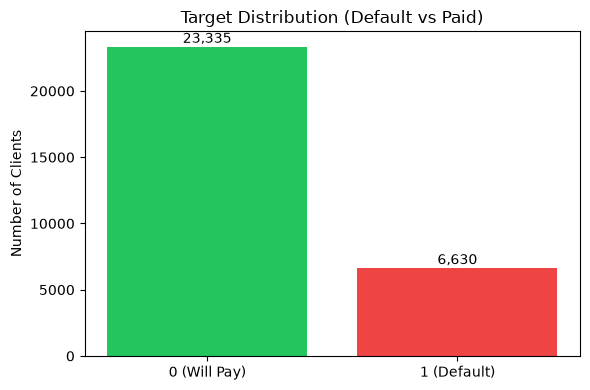

In [18]:
# Target distribution visualization
vc = df["default.payment.next.month"].value_counts().sort_index()
plt.figure(figsize=(6, 4))
bars = plt.bar(["0 (Will Pay)", "1 (Default)"], vc.values, color=["#22c55e", "#ef4444"])
plt.title("Target Distribution (Default vs Paid)")
plt.ylabel("Number of Clients")
for b in bars:
    plt.text(b.get_x() + b.get_width()/2, b.get_height() + 300, f"{int(b.get_height()):,}", ha="center")
plt.tight_layout()
plt.show()


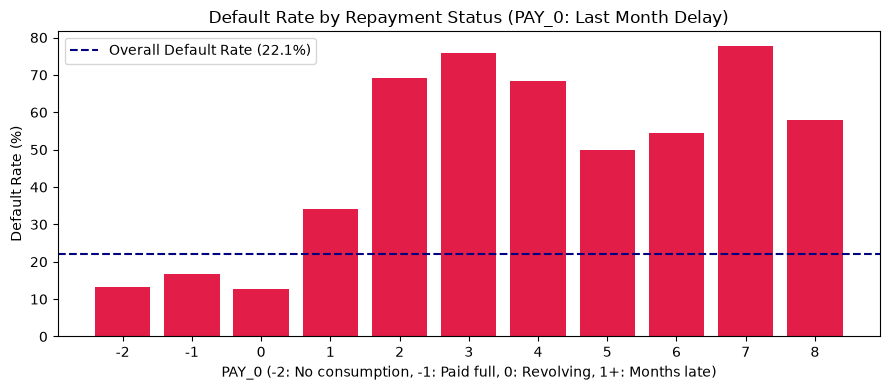

In [19]:
# Default Rate by Repayment Status (PAY_0 - most critical feature)
pay_rate = df.groupby("PAY_0")["default.payment.next.month"].mean() * 100
plt.figure(figsize=(9, 4))
bars = plt.bar([str(i) for i in pay_rate.index], pay_rate.values, color="#e11d48")
plt.title("Default Rate by Repayment Status (PAY_0: Last Month Delay)")
plt.xlabel("PAY_0 (-2: No consumption, -1: Paid full, 0: Revolving, 1+: Months late)")
plt.ylabel("Default Rate (%)")
plt.axhline(df["default.payment.next.month"].mean() * 100, color="navy", linestyle="--", label="Overall Default Rate (22.1%)")
plt.legend()
plt.tight_layout()
plt.show()


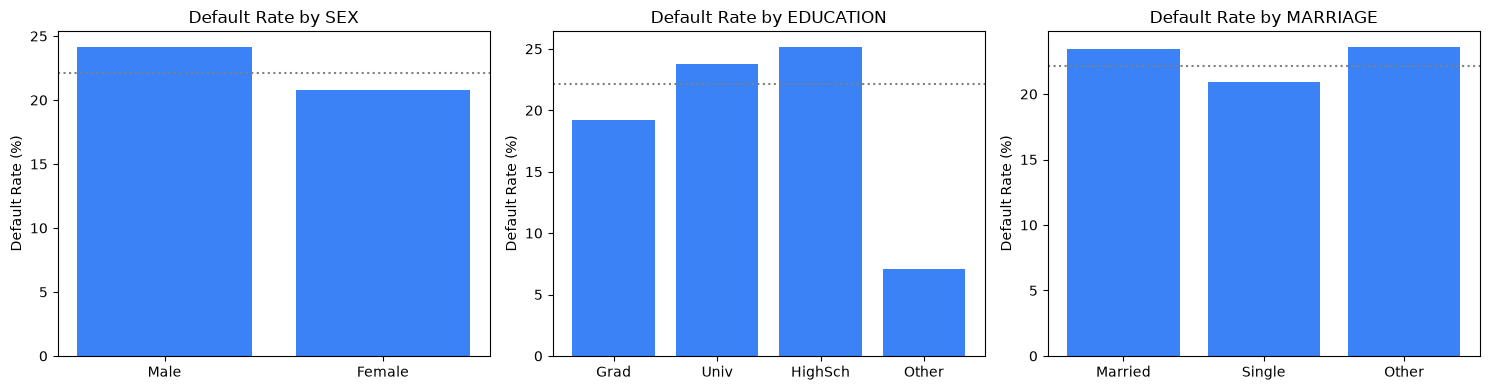

In [20]:
# Default Rate across Demographics
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
demographics = [("SEX", ["Male", "Female"]), ("EDUCATION", ["Grad", "Univ", "HighSch", "Other"]), ("MARRIAGE", ["Married", "Single", "Other"])]

for ax, (col, labels) in zip(axes, demographics):
    rates = df.groupby(col)["default.payment.next.month"].mean() * 100
    ax.bar(labels, rates.values, color="#3b82f6")
    ax.set_title(f"Default Rate by {col}")
    ax.set_ylabel("Default Rate (%)")
    ax.axhline(df["default.payment.next.month"].mean() * 100, color="gray", linestyle=":")

plt.tight_layout()
plt.show()


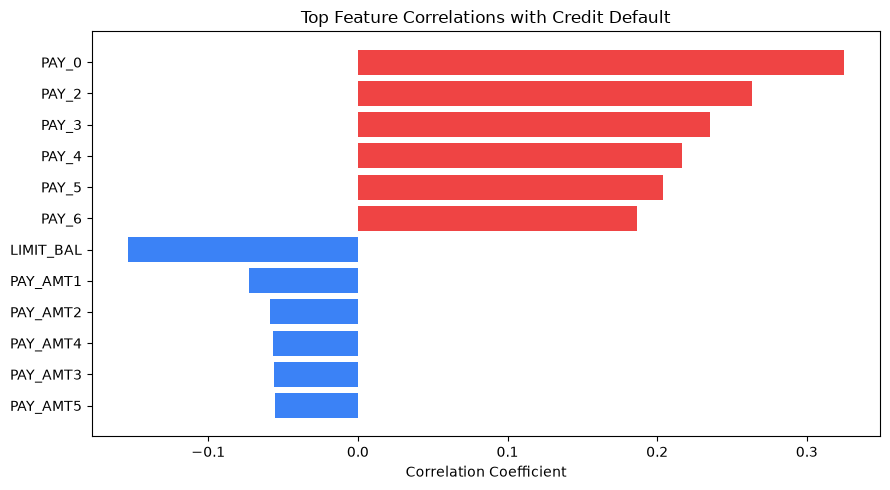

In [21]:
# Correlation with Target
corr = df.corr()["default.payment.next.month"].drop("default.payment.next.month")
top_corr = corr.reindex(corr.abs().sort_values(ascending=False).index).head(12)

plt.figure(figsize=(9, 5))
colors = ["#ef4444" if val > 0 else "#3b82f6" for val in top_corr.values]
plt.barh([str(c) for c in top_corr.index[::-1]], top_corr.values[::-1], color=colors[::-1])
plt.title("Top Feature Correlations with Credit Default")
plt.xlabel("Correlation Coefficient")
plt.tight_layout()
plt.show()


--------------
# *Feature Engineering*
#### Derive practical financial indicators without complex pipelines
--------------


In [22]:
limit = df["LIMIT_BAL"].replace(0, np.nan)

# 1. Immediate credit utilization
df["credit_utilization"] = (df["BILL_AMT1"] / limit).fillna(0.0)

# 2. 6-Month average credit utilization
bill_cols = ["BILL_AMT1", "BILL_AMT2", "BILL_AMT3", "BILL_AMT4", "BILL_AMT5", "BILL_AMT6"]
df["avg_utilization_6m"] = (df[bill_cols].mean(axis=1) / limit).fillna(0.0)

# 3. Delinquency frequency (count of late months)
pay_cols = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
df["late_months"] = (df[pay_cols] > 0).sum(axis=1).astype(float)

# 4. Maximum repayment delay
df["max_delay_months"] = df[pay_cols].max(axis=1).astype(float)

# 5. Payment to Bill ratio (are they paying off their statement?)
df["payment_to_bill_ratio"] = (df["PAY_AMT1"] / (df["BILL_AMT1"].abs() + 1.0)).clip(0.0, 20.0)

# 6. Bill trend over 6 months (debt growth)
df["bill_trend_6m"] = (df["BILL_AMT1"] - df["BILL_AMT6"]).astype(float)

df[["credit_utilization", "avg_utilization_6m", "late_months", "max_delay_months", "payment_to_bill_ratio", "bill_trend_6m"]].head()


,credit_utilization,avg_utilization_6m,late_months,max_delay_months,payment_to_bill_ratio,bill_trend_6m
0,0.195650,0.064200,2.0,2.0,0.000000,3913.0
1,0.022350,0.023718,2.0,2.0,0.000000,-579.0
2,0.324878,0.188246,0.0,0.0,0.051915,13690.0
3,0.939800,0.771113,0.0,0.0,0.042561,17443.0
4,0.172340,0.364463,0.0,0.0,0.232072,-10514.0


--------------
# *Data Modelling*
#### Split data, scale with StandardScaler, and train classifiers directly (NO PIPELINE)
--------------


In [23]:
X = df.drop("default.payment.next.month", axis=1)
y = df["default.payment.next.month"]


In [24]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


In [25]:
X_train.head()


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,credit_utilization,avg_utilization_6m,late_months,max_delay_months,payment_to_bill_ratio,bill_trend_6m
27394,300000.0,1,2,1,35,-2,-2,-2,-2,-2,-2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00000,0.000000,0.0,-2.0,0.000000,0.0
15341,50000.0,2,3,3,37,2,2,2,2,2,2,47676.0,48896.0,49325.0,48033.0,27019.0,26450.0,2300.0,1500.0,0.0,3400.0,0.0,1200.0,0.95352,0.824663,6.0,2.0,0.048241,21226.0
26617,80000.0,1,1,2,23,-1,-1,-1,-1,0,0,444.0,444.0,444.0,888.0,888.0,444.0,444.0,444.0,888.0,444.0,0.0,1038.0,0.00555,0.007400,0.0,0.0,0.997753,0.0
21600,50000.0,2,2,2,26,-1,-1,-1,-1,-1,-1,390.0,2078.0,390.0,390.0,0.0,780.0,2078.0,390.0,390.0,0.0,780.0,0.0,0.00780,0.013427,0.0,-1.0,5.314578,-390.0
11563,200000.0,1,2,2,30,-2,-2,-2,-2,-2,-2,48492.0,49934.0,24753.0,123439.0,132269.0,129224.0,20294.0,24891.0,125171.0,17816.0,26269.0,4349.0,0.24246,0.423426,0.0,-2.0,0.418493,-80732.0


In [26]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [27]:
X_train_scaled[:5]


array([[ 1.02202404e+00, -1.22974045e+00,  2.15888860e-01,
        -1.07045295e+00, -5.02640949e-02, -1.77194733e+00,
        -1.56649410e+00, -1.54426568e+00, -1.53003683e+00,
        -1.53879369e+00, -1.49253378e+00, -7.00030288e-01,
        -6.94463702e-01, -6.78530941e-01, -6.74057035e-01,
        -6.65084911e-01, -6.52938295e-01, -3.38845795e-01,
        -2.45684948e-01, -2.94972804e-01, -3.20891993e-01,
        -3.18684218e-01, -2.89318988e-01, -1.03185872e+00,
        -1.06266327e+00, -5.36972236e-01, -1.82027193e+00,
        -3.00700916e-01, -2.84425735e-01],
       [-9.03019952e-01,  8.13179723e-01,  1.56151750e+00,
         2.76038950e+00,  1.67212827e-01,  1.79373829e+00,
         1.78105746e+00,  1.81835916e+00,  1.90681127e+00,
         2.01025861e+00,  2.00501208e+00, -4.90789740e-02,
        -5.58153253e-03,  3.21151082e-02,  7.23242279e-02,
        -2.20083920e-01, -2.08967730e-01, -2.00959924e-01,
        -1.83577689e-01, -2.94972804e-01, -9.39381843e-02,
        -3.18

### Model 1: Logistic Regression


In [28]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_score

model_lr = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)
model_lr.fit(X_train_scaled, y_train)

y_pred_lr = model_lr.predict(X_test_scaled)
y_prob_lr = model_lr.predict_proba(X_test_scaled)[:, 1]

print("Logistic Regression Accuracy:", accuracy_score(y_test, y_pred_lr))
print("ROC-AUC Score:", roc_auc_score(y_test, y_prob_lr))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_lr))
print("\nClassification Report:\n", classification_report(y_test, y_pred_lr))

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores_lr = cross_val_score(model_lr, X_train_scaled, y_train, cv=cv, scoring="roc_auc")
print("Mean CV ROC-AUC:", cv_scores_lr.mean(), "Std:", cv_scores_lr.std())


Logistic Regression Accuracy: 0.7472050725846822
ROC-AUC Score: 0.7521429464799056

Confusion Matrix:
 [[3680  987]
 [ 528  798]]

Classification Report:
               precision    recall  f1-score   support

           0       0.87      0.79      0.83      4667
           1       0.45      0.60      0.51      1326

    accuracy                           0.75      5993
   macro avg       0.66      0.70      0.67      5993
weighted avg       0.78      0.75      0.76      5993

Mean CV ROC-AUC: 0.7589131624649397 Std: 0.010621325197707497


### Model 2: Decision Tree Classifier


In [29]:
from sklearn.tree import DecisionTreeClassifier

model_dt = DecisionTreeClassifier(max_depth=6, min_samples_leaf=30, random_state=42)
model_dt.fit(X_train, y_train)

y_pred_dt = model_dt.predict(X_test)
y_prob_dt = model_dt.predict_proba(X_test)[:, 1]

print("Decision Tree Accuracy:", accuracy_score(y_test, y_pred_dt))
print("ROC-AUC Score:", roc_auc_score(y_test, y_prob_dt))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_dt))
print("\nClassification Report:\n", classification_report(y_test, y_pred_dt))


Decision Tree Accuracy: 0.8161188052728183
ROC-AUC Score: 0.7519575201642028

Confusion Matrix:
 [[4428  239]
 [ 863  463]]

Classification Report:
               precision    recall  f1-score   support

           0       0.84      0.95      0.89      4667
           1       0.66      0.35      0.46      1326

    accuracy                           0.82      5993
   macro avg       0.75      0.65      0.67      5993
weighted avg       0.80      0.82      0.79      5993


### Model 3: Random Forest Classifier


In [30]:
from sklearn.ensemble import RandomForestClassifier

model_rf = RandomForestClassifier(n_estimators=150, max_depth=10, min_samples_split=20, random_state=42, n_jobs=-1)
model_rf.fit(X_train, y_train)

y_pred_rf = model_rf.predict(X_test)
y_prob_rf = model_rf.predict_proba(X_test)[:, 1]

print("Random Forest Accuracy:", accuracy_score(y_test, y_pred_rf))
print("ROC-AUC Score:", roc_auc_score(y_test, y_prob_rf))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_rf))
print("\nClassification Report:\n", classification_report(y_test, y_pred_rf))


Random Forest Accuracy: 0.8184548640080094
ROC-AUC Score: 0.7744509037977572

Confusion Matrix:
 [[4423  244]
 [ 844  482]]

Classification Report:
               precision    recall  f1-score   support

           0       0.84      0.95      0.89      4667
           1       0.66      0.36      0.47      1326

    accuracy                           0.82      5993
   macro avg       0.75      0.66      0.68      5993
weighted avg       0.80      0.82      0.80      5993


### Model 4: XGBoost Classifier


In [31]:
from xgboost import XGBClassifier

model_xgb = XGBClassifier(n_estimators=150, max_depth=4, learning_rate=0.08, eval_metric="logloss", random_state=42, n_jobs=-1)
model_xgb.fit(X_train, y_train)

y_pred_xgb = model_xgb.predict(X_test)
y_prob_xgb = model_xgb.predict_proba(X_test)[:, 1]

print("XGBoost Accuracy:", accuracy_score(y_test, y_pred_xgb))
print("ROC-AUC Score:", roc_auc_score(y_test, y_prob_xgb))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_xgb))
print("\nClassification Report:\n", classification_report(y_test, y_pred_xgb))


XGBoost Accuracy: 0.8197897547138328
ROC-AUC Score: 0.7796646554981044

Confusion Matrix:
 [[4438  229]
 [ 851  475]]

Classification Report:
               precision    recall  f1-score   support

           0       0.84      0.95      0.89      4667
           1       0.67      0.36      0.47      1326

    accuracy                           0.82      5993
   macro avg       0.76      0.65      0.68      5993
weighted avg       0.80      0.82      0.80      5993


--------------
# *Model Comparison & Best Model Selection*
--------------


In [32]:
comparison_df = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree", "Random Forest", "XGBoost"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_xgb),
    ],
    "ROC_AUC": [
        roc_auc_score(y_test, y_prob_lr),
        roc_auc_score(y_test, y_prob_dt),
        roc_auc_score(y_test, y_prob_rf),
        roc_auc_score(y_test, y_prob_xgb),
    ]
}).sort_values(by="ROC_AUC", ascending=False).reset_index(drop=True)

comparison_df


,Model,Accuracy,ROC_AUC
0,XGBoost,0.819790,0.779665
1,Random Forest,0.818455,0.774451
2,Logistic Regression,0.747205,0.752143
3,Decision Tree,0.816119,0.751958


--------------
### *Save Best Model and Scaler for Production Inference (NO PIPELINE)*
--------------


In [33]:
import joblib

# Persist the top performing model and scaler
joblib.dump(model_xgb, "models/best_model.joblib")
joblib.dump(scaler, "models/scaler.joblib")

print("Saved -> models/best_model.joblib")
print("Saved -> models/scaler.joblib")
print("Training completed without Pipeline!")


Saved -> models/best_model.joblib
Saved -> models/scaler.joblib
Training completed without Pipeline!
